# 01 · 检测基础：框、IoU、NMS 与 mAP

> 这一本不训练模型。它先把你读 YOLO 代码时最常卡住的 5 个概念拆开：
> **边界框格式、IoU、NMS、Precision/Recall/AP、YOLO 的网格思想**。
>
> 先把这些“零件”弄懂，再去读 YOLOv1 和 YOLOv8 的实现，会轻松很多。

学习顺序：

1. 一个框有几种写法？怎样互转？
2. 两个框有多重合？→ IoU
3. 一堆重复框怎么办？→ NMS
4. 怎样评价检测器好坏？→ Precision / Recall / AP / mAP
5. YOLO 凭什么“只看一次”？→ 网格 + 回归

## 1. 边界框：四种写法

| 名称 | 形式 | 谁常用 | 注意 |
|---|---|---|---|
| `xyxy` | `(x1, y1, x2, y2)` | 画图、NMS、torchvision | 左上角 + 右下角 |
| `xywh` | `(x, y, w, h)` | OpenCV、COCO | 这里的 `x,y` 是**左上角** |
| `cxcywh` | `(cx, cy, w, h)` | YOLO 标签、锚框 | 这里的 `cx,cy` 是**中心点** |
| 归一化 `cxcywh` | 各值除以宽高 | YOLO 的 `.txt` 标签 | 取值一般在 `[0,1]` |

最容易犯的错：把 `xywh` 的 `x,y` 当成中心点。YOLO 标签里的 `x,y` 是**中心点**，而且是归一化的。

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import rcParams
from PIL import Image, ImageDraw

rcParams.update({
    "figure.dpi": 110,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})
rng = np.random.default_rng(2024)

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("工作目录:", Path.cwd())

Python : 3.11.17
NumPy  : 2.4.6
工作目录: d:\Models\YOLO


In [2]:
# 画一个简单的“街景”，后面都用它讲坐标
W = H = 360

def make_street_scene():
    yy, xx = np.mgrid[0:H, 0:W]
    img = np.zeros((H, W, 3), dtype=np.uint8)
    # 天空渐变
    t = np.clip(yy / 250, 0, 1)[..., None]
    sky = (1 - t) * np.array([238, 246, 255]) + t * np.array([176, 205, 238])
    img[:] = sky.astype(np.uint8)
    # 地面
    img[245:] = np.array([196, 207, 190], dtype=np.uint8)
    pil = Image.fromarray(img)
    d = ImageDraw.Draw(pil)

    # 车
    d.rounded_rectangle([32, 245, 172, 296], radius=12, fill=(205, 66, 60))
    d.rectangle([62, 218, 142, 250], fill=(225, 92, 84))
    d.ellipse([48, 282, 78, 312], fill=(35, 35, 40))
    d.ellipse([126, 282, 156, 312], fill=(35, 35, 40))
    # 人
    d.ellipse([230, 154, 262, 186], fill=(238, 190, 150))
    d.rounded_rectangle([226, 186, 266, 284], radius=10, fill=(55, 105, 190))
    d.line([236, 284, 232, 318], fill=(40, 45, 60), width=8)
    d.line([256, 284, 260, 318], fill=(40, 45, 60), width=8)
    # 路牌
    d.rectangle([308, 92, 344, 166], fill=(240, 196, 54))
    d.rectangle([320, 166, 330, 250], fill=(120, 120, 125))
    return np.asarray(pil)

image = make_street_scene()
gt_boxes = np.array([
    [24, 212, 176, 315],    # car
    [218, 146, 274, 325],   # person
    [300, 86, 350, 252],    # sign
], dtype=np.float32)
gt_labels = ["car", "person", "sign"]
print("图像尺寸 (H, W):", image.shape[:2])
print("框的数量:", len(gt_boxes))

图像尺寸 (H, W): (360, 360)
框的数量: 3


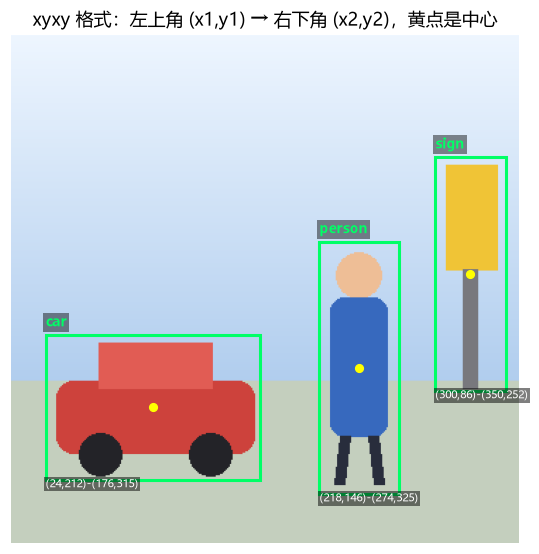

In [3]:
def draw_boxes(ax, boxes, labels=None, color="lime", lw=2, fmt=None):
    for i, box in enumerate(boxes):
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor=color, linewidth=lw))
        if labels is not None:
            ax.text(x1, max(y1 - 6, 2), str(labels[i]), color=color,
                    fontsize=9, weight="bold",
                    bbox=dict(facecolor="black", alpha=0.45, pad=1.5, edgecolor="none"))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image)
draw_boxes(ax, gt_boxes, gt_labels, color="#00ff66")
for i, (x1, y1, x2, y2) in enumerate(gt_boxes):
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    ax.plot(cx, cy, "o", color="yellow", markersize=5)
    ax.text(x1, y2 + 5, f"({x1:.0f},{y1:.0f})-({x2:.0f},{y2:.0f})",
            color="white", fontsize=7,
            bbox=dict(facecolor="black", alpha=0.5, pad=1, edgecolor="none"))
ax.set_title("xyxy 格式：左上角 (x1,y1) → 右下角 (x2,y2)，黄点是中心")
ax.axis("off")
plt.show()

### 1.1 互转公式

从 `xyxy` 到 `cxcywh`：

$$
c_x=\frac{x_1+x_2}{2},\quad c_y=\frac{y_1+y_2}{2},\quad w=x_2-x_1,\quad h=y_2-y_1
$$

从 `cxcywh` 到 `xyxy`：

$$
x_1=c_x-\frac{w}{2},\quad y_1=c_y-\frac{h}{2},\quad x_2=c_x+\frac{w}{2},\quad y_2=c_y+\frac{h}{2}
$$

YOLO 的标签还会再除以图像宽高，变成 `[0,1]` 的小数。这样换分辨率时不用改标签。

In [4]:
def xyxy_to_cxcywh(boxes):
    boxes = np.asarray(boxes, dtype=np.float32)
    x1, y1, x2, y2 = boxes.T
    return np.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], axis=-1)

def cxcywh_to_xyxy(boxes):
    boxes = np.asarray(boxes, dtype=np.float32)
    cx, cy, w, h = boxes.T
    return np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=-1)

def normalize_cxcywh(boxes, width, height):
    scale = np.array([width, height, width, height], dtype=np.float32)
    return np.asarray(boxes, dtype=np.float32) / scale

def denormalize_cxcywh(boxes, width, height):
    scale = np.array([width, height, width, height], dtype=np.float32)
    return np.asarray(boxes, dtype=np.float32) * scale

boxes_cxcywh = xyxy_to_cxcywh(gt_boxes)
boxes_normalized = normalize_cxcywh(boxes_cxcywh, W, H)
roundtrip = cxcywh_to_xyxy(denormalize_cxcywh(boxes_normalized, W, H))

print("xyxy 像素:\n", gt_boxes)
print("\ncxcywh 像素:\n", np.round(boxes_cxcywh, 2))
print("\n归一化 cxcywh:\n", np.round(boxes_normalized, 4))
print("\n往返误差:", np.abs(roundtrip - gt_boxes).max())
assert np.allclose(roundtrip, gt_boxes, atol=1e-5)

xyxy 像素:
 [[ 24. 212. 176. 315.]
 [218. 146. 274. 325.]
 [300.  86. 350. 252.]]

cxcywh 像素:
 [[100.  263.5 152.  103. ]
 [246.  235.5  56.  179. ]
 [325.  169.   50.  166. ]]

归一化 cxcywh:
 [[0.2778 0.7319 0.4222 0.2861]
 [0.6833 0.6542 0.1556 0.4972]
 [0.9028 0.4694 0.1389 0.4611]]

往返误差: 1.5258789e-05


> **YOLO 标签示例**：一张 `640×480` 的图里有一个中心在 `(320, 240)`、大小 `128×96` 的 `person`（类别 id=0）：
>
> ```text
> 0 0.500000 0.500000 0.200000 0.200000
> ```
>
> 五列分别是 `class cx cy w h`，后四个都除以了图像宽高。

## 2. IoU：两个框有多重合？

IoU（Intersection over Union）＝交集面积 ÷ 并集面积：

$$
\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}
=\frac{|A\cap B|}{|A|+|B|-|A\cap B|}
$$

- `IoU = 0`：完全不相交
- `IoU = 1`：完全重合
- 检测里常用阈值：`0.5`（PASCAL VOC）、`0.5:0.95`（COCO）

为什么不用“中心点距离”？因为两个大小差很多的框，中心可能很近，但完全不是同一个物体。IoU 同时考虑位置和大小。

In [5]:
def box_iou(boxes1, boxes2):
    '''boxes1: [N,4], boxes2: [M,4], 均为 xyxy。返回 [N,M]。'''
    b1 = np.asarray(boxes1, dtype=np.float32)[:, None, :]
    b2 = np.asarray(boxes2, dtype=np.float32)[None, :, :]
    lt = np.maximum(b1[..., :2], b2[..., :2])
    rb = np.minimum(b1[..., 2:], b2[..., 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area1 = np.clip(b1[..., 2] - b1[..., 0], 0, None) * np.clip(b1[..., 3] - b1[..., 1], 0, None)
    area2 = np.clip(b2[..., 2] - b2[..., 0], 0, None) * np.clip(b2[..., 3] - b2[..., 1], 0, None)
    union = area1 + area2 - inter
    return inter / np.clip(union, 1e-9, None)

demo_boxes = np.array([
    [30, 40, 130, 140],
    [35, 45, 132, 138],
    [160, 50, 260, 150],
    [30, 40, 80, 90],
    [200, 200, 300, 280],
], dtype=np.float32)
iou = box_iou(demo_boxes, demo_boxes)
np.round(iou, 3)

array([[1.   , 0.867, 0.   , 0.25 , 0.   ],
       [0.867, 1.   , 0.   , 0.213, 0.   ],
       [0.   , 0.   , 1.   , 0.   , 0.   ],
       [0.25 , 0.213, 0.   , 1.   , 0.   ],
       [0.   , 0.   , 0.   , 0.   , 1.   ]], dtype=float32)

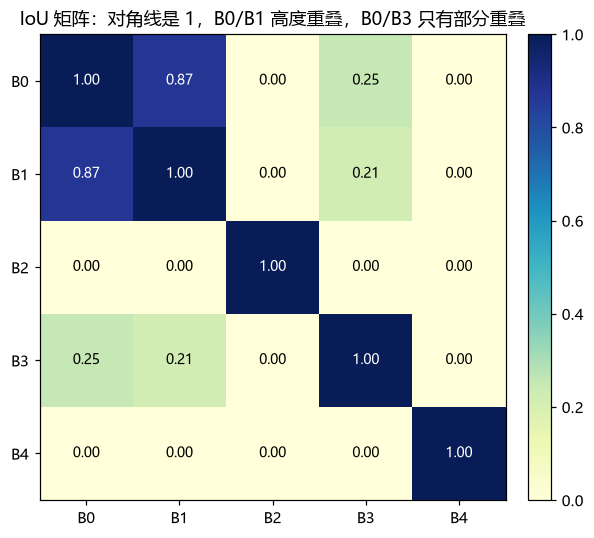

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(iou, cmap="YlGnBu", vmin=0, vmax=1)
for i in range(len(demo_boxes)):
    for j in range(len(demo_boxes)):
        ax.text(j, i, f"{iou[i, j]:.2f}", ha="center", va="center",
                color="white" if iou[i, j] > 0.55 else "black", fontsize=9)
ax.set_xticks(range(len(demo_boxes)), [f"B{i}" for i in range(len(demo_boxes))])
ax.set_yticks(range(len(demo_boxes)), [f"B{i}" for i in range(len(demo_boxes))])
ax.set_title("IoU 矩阵：对角线是 1，B0/B1 高度重叠，B0/B3 只有部分重叠")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()

### 2.1 交集面积怎么算？

两个矩形的交集还是一个矩形：

$$
x_1^{\cap}=\max(x_1^A,x_1^B),\quad y_1^{\cap}=\max(y_1^A,y_1^B)
$$
$$
x_2^{\cap}=\min(x_2^A,x_2^B),\quad y_2^{\cap}=\min(y_2^A,y_2^B)
$$

如果 `x2_cap <= x1_cap` 或 `y2_cap <= y1_cap`，交集就是 0。上面的 `np.clip(..., 0, None)` 就是在处理这种情况。

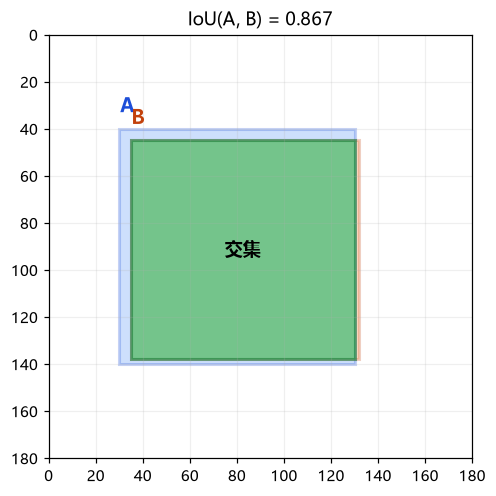

In [7]:
def show_pair_iou(a, b):
    iou_value = box_iou(a[None], b[None])[0, 0]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.add_patch(patches.Rectangle(a[:2], a[2] - a[0], a[3] - a[1],
                                   facecolor="#3b82f6", alpha=0.25, edgecolor="#1d4ed8", lw=2))
    ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1],
                                   facecolor="#f97316", alpha=0.25, edgecolor="#c2410c", lw=2))
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    if ix2 > ix1 and iy2 > iy1:
        ax.add_patch(patches.Rectangle((ix1, iy1), ix2 - ix1, iy2 - iy1,
                                       facecolor="#22c55e", alpha=0.55, edgecolor="#15803d", lw=2))
        ax.text((ix1 + ix2) / 2, (iy1 + iy2) / 2, "交集", ha="center", va="center",
                fontsize=12, weight="bold")
    ax.text(a[0], a[1] - 7, "A", color="#1d4ed8", weight="bold", fontsize=13)
    ax.text(b[0], b[1] - 7, "B", color="#c2410c", weight="bold", fontsize=13)
    ax.set_xlim(0, 180)
    ax.set_ylim(180, 0)
    ax.set_aspect("equal")
    ax.set_title(f"IoU(A, B) = {iou_value:.3f}")
    ax.grid(alpha=0.2)
    plt.show()

show_pair_iou(np.array([30, 40, 130, 140]), np.array([35, 45, 132, 138]))

## 3. NMS：把重复框压掉

YOLO 会在很多网格、很多预测框上给出“这里有物体”的分数。同一个物体会被重复检测很多次。

**NMS（Non-Maximum Suppression，非极大值抑制）** 的流程：

1. 按置信度从高到低排序。
2. 取分数最高的框，保留它。
3. 删掉与它 IoU 大于阈值的其它框（认为在说同一个物体）。
4. 重复 2–3，直到没有框。

> 注意：YOLO 的“置信度”通常是 `objectness × class_prob`。NMS 一般是**按类别分别做**的——猫和狗即使框重叠，也不应该互相抑制。

In [8]:
def nms(boxes, scores, iou_thres=0.45):
    '''单类别 NMS。boxes: [N,4] xyxy；scores: [N]。返回保留的下标。'''
    boxes = np.asarray(boxes, dtype=np.float32)
    scores = np.asarray(scores, dtype=np.float32)
    order = scores.argsort()[::-1]
    keep = []
    while order.size > 0:
        i = int(order[0])
        keep.append(i)
        if order.size == 1:
            break
        rest = order[1:]
        ious = box_iou(boxes[i:i + 1], boxes[rest])[0]
        order = rest[ious <= iou_thres]
    return np.array(keep, dtype=np.int64)

boxes = np.array([
    [30, 40, 130, 145],    # A1
    [34, 44, 132, 142],    # A2 与 A1 重复
    [155, 55, 255, 160],   # B1
    [160, 60, 250, 155],   # B2 与 B1 重复
    [95, 165, 190, 260],   # C1
    [100, 170, 188, 255],  # C2 与 C1 重复
    [10, 10, 60, 60],      # 一个孤立的低分框
], dtype=np.float32)
scores = np.array([0.95, 0.88, 0.92, 0.70, 0.85, 0.60, 0.55], dtype=np.float32)
classes = np.array([0, 0, 1, 1, 2, 2, 0], dtype=np.int64)

keep = nms(boxes, scores, iou_thres=0.45)
print("保留的下标:", keep)
print("被抑制的下标:", sorted(set(range(len(boxes))) - set(keep.tolist())))

保留的下标: [0 2 4 6]
被抑制的下标: [1, 3, 5]


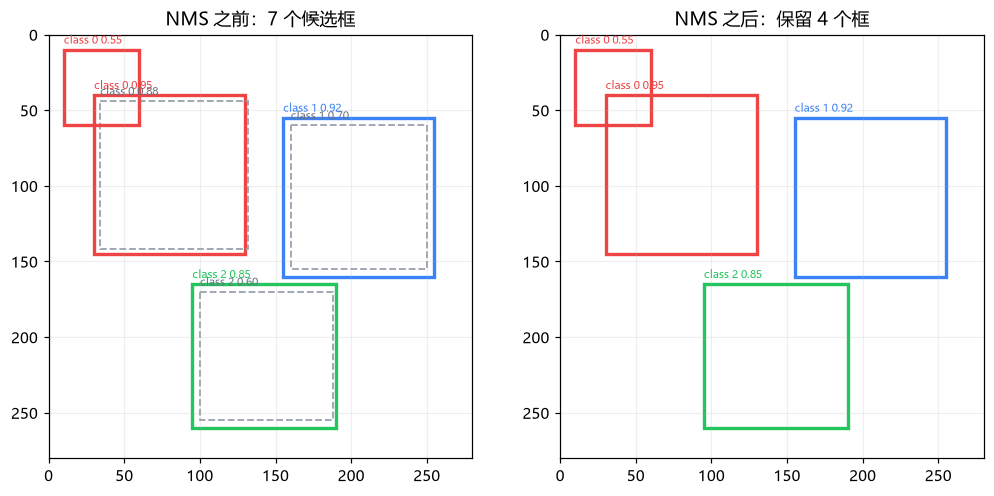

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
colors = {0: "#ef4444", 1: "#3b82f6", 2: "#22c55e"}
names = {0: "class 0", 1: "class 1", 2: "class 2"}

for ax, title, selected in [
    (axes[0], "NMS 之前：7 个候选框", range(len(boxes))),
    (axes[1], "NMS 之后：保留 4 个框", keep),
]:
    ax.set_xlim(0, 280)
    ax.set_ylim(280, 0)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.set_title(title)
    for idx in selected:
        b = boxes[idx]
        kept = idx in set(keep.tolist())
        ax.add_patch(patches.Rectangle(
            b[:2], b[2] - b[0], b[3] - b[1],
            fill=False, lw=2.2 if kept else 1.2,
            edgecolor=colors[classes[idx]] if kept else "#9ca3af",
            linestyle="-" if kept else "--",
        ))
        ax.text(b[0], b[1] - 4, f"{names[classes[idx]]} {scores[idx]:.2f}",
                fontsize=7.5, color=colors[classes[idx]] if kept else "#6b7280")
plt.show()

### 3.1 NMS 的阈值在控制什么？

> 上面的 `nms()` 为了聚焦流程，只演示了**单类别** NMS。真实的多类检测会对每个类别分别调用一次；不同类别的框即使重叠，也不会互相抑制。

- 阈值**小**（如 0.3）：抑制更激进，重复框少，但相邻的两个真实物体可能被误删。
- 阈值**大**（如 0.7）：保留更多框，召回高，但重复框多。

所以部署时通常要同时调 `conf_thres`（先过滤低分框）和 `iou_thres`（再压重复框）。YOLOv8 的 `model.predict(conf=..., iou=...)` 就是这两个参数。

## 4. 评价检测器：Precision、Recall、AP、mAP

先把每个预测框和真实框（GT）按 IoU 匹配：

- **TP**：预测框和某个 GT 的 IoU ≥ 阈值，且类别正确，且该 GT 没被匹配过。
- **FP**：没有匹配上任何 GT 的预测框（包括定位太差、类别错、背景误检）。
- **FN**：没有被任何预测框匹配上的 GT（漏检）。

$$
\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN}
$$

- Precision 高：报出来的框大多是对的（少误报）。
- Recall 高：真实物体大多被找到了（少漏报）。

**AP（Average Precision）** 是 Precision-Recall 曲线下的面积，综合看不同置信度阈值下的表现。**mAP** 是各类别 AP 的平均。

In [10]:
# 一个 4 个 GT、8 个预测框的小例子（已按置信度从高到低排好）
scores = np.array([0.95, 0.91, 0.88, 0.84, 0.80, 0.72, 0.65, 0.60])
is_tp  = np.array([1,    1,    0,    1,    0,    0,    1,    0], dtype=bool)
total_gt = 4

tp_cum = np.cumsum(is_tp)
fp_cum = np.cumsum(~is_tp)
precision = tp_cum / (tp_cum + fp_cum)
recall = tp_cum / total_gt

print(f"{'rank':>4} {'score':>6} {'TP?':>4} {'precision':>9} {'recall':>7}")
for i in range(len(scores)):
    print(f"{i+1:>4} {scores[i]:>6.2f} {str(bool(is_tp[i])):>4} {precision[i]:>9.3f} {recall[i]:>7.3f}")

rank  score  TP? precision  recall
   1   0.95 True     1.000   0.250
   2   0.91 True     1.000   0.500
   3   0.88 False     0.667   0.500
   4   0.84 True     0.750   0.750
   5   0.80 False     0.600   0.750
   6   0.72 False     0.500   0.750
   7   0.65 True     0.571   1.000
   8   0.60 False     0.500   1.000


AP = 0.8304


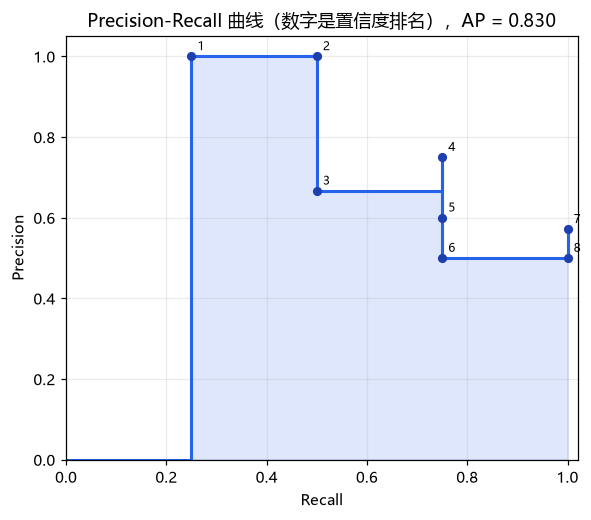

In [11]:
def average_precision(recall, precision):
    '''VOC2010+ 的 all-point AP：先做 precision 包络，再对 recall 积分。'''
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([0.0], precision, [0.0]))
    # 从右往左取最大 precision，得到单调不增的包络
    mpre = np.maximum.accumulate(mpre[::-1])[::-1]
    return float(np.sum(np.diff(mrec) * mpre[:-1]))

ap = average_precision(recall, precision)
print(f"AP = {ap:.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.step(np.r_[0, recall], np.r_[0, precision], where="post", color="#2563eb", lw=2)
ax.fill_between(np.r_[0, recall], 0, np.r_[0, precision], step="post", alpha=0.15, color="#2563eb")
ax.scatter(recall, precision, color="#1e40af", s=25, zorder=3)
for i, (r, p) in enumerate(zip(recall, precision)):
    ax.annotate(str(i + 1), (r, p), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Precision-Recall 曲线（数字是置信度排名），AP = {ap:.3f}")
ax.grid(alpha=0.25)
plt.show()

### 4.1 为什么 mAP 有很多种写法？

| 指标 | 含义 |
|---|---|
| `AP@0.5` | IoU 阈值固定 0.5 时的 AP（VOC 常用） |
| `AP@[.5:.95]` | IoU 从 0.5 到 0.95、步长 0.05，取 10 个阈值的平均（COCO 主指标） |
| `mAP` | 所有类别的 AP 再平均 |
| `mAP50` / `mAP50-95` | Ultralytics 训练日志里的两个常见列 |

所以看到“mAP 50.2”时，一定要问清楚：**是哪个数据集、哪个 IoU 阈值、几个类别平均**。不同口径不能直接比。

## 5. YOLO 的核心直觉：把检测变成一次回归

在 YOLO 之前，R-CNN 系列是“先找候选区域，再分类”。YOLO 的想法是：

> 把图像切成 $S\times S$ 的网格。每个网格负责预测**中心点落在它里面**的物体。
> 每个网格直接回归出 $B$ 个框、置信度和类别概率。整张图只过一遍网络。

以 YOLOv1 的 PASCAL VOC 设置为例子：$S=7$，$B=2$，$C=20$。

每个网格的输出是：

$$
B\times(4+1)+C = 2\times(4+1)+20=30
$$

整张图的输出张量：

$$
7\times7\times30=1470
$$

这 1470 个数就包含了整张图的检测结果。没有 RPN，没有 RoI pooling，没有第二步分类器。

In [12]:
S, B, C = 7, 2, 20
per_cell = B * (4 + 1) + C
total = S * S * per_cell

print(f"每个网格: B*(4+1)+C = {B}*(4+1)+{C} = {per_cell}")
print(f"整张图 : S*S*{per_cell} = {S}*{S}*{per_cell} = {total}")
print(f"reshape 后: ({S}, {S}, {per_cell})")

每个网格: B*(4+1)+C = 2*(4+1)+20 = 30
整张图 : S*S*30 = 7*7*30 = 1470
reshape 后: (7, 7, 30)


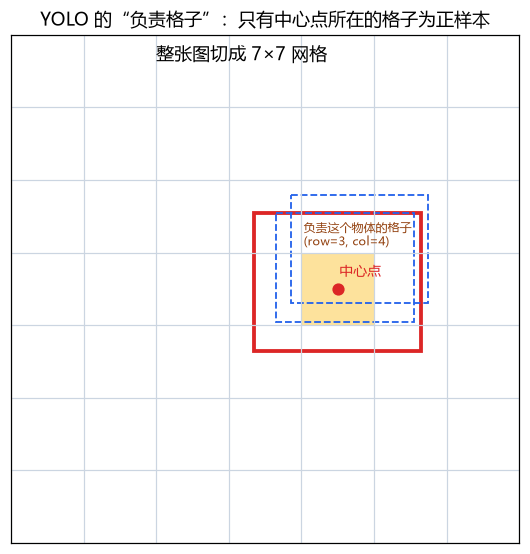

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
S = 7
cell = 1.0
ax.set_xlim(0, S)
ax.set_ylim(S, 0)
ax.set_aspect("equal")
for k in range(S + 1):
    ax.axhline(k, color="#cbd5e1", lw=0.8)
    ax.axvline(k, color="#cbd5e1", lw=0.8)

# 假设物体中心落在第 3 行、第 4 列（从 0 开始）
row, col = 3, 4
ax.add_patch(patches.Rectangle((col, row), 1, 1, facecolor="#fbbf24", alpha=0.45))
ax.add_patch(patches.Rectangle((col - 0.65, row - 0.55), 2.3, 1.9,
                               fill=False, edgecolor="#dc2626", lw=2.5))
ax.plot(col + 0.5, row + 0.5, "o", color="#dc2626", markersize=7)
ax.text(col + 0.52, row + 0.32, "中心点", color="#dc2626", fontsize=9)
ax.text(2.0, 0.35, "整张图切成 7×7 网格", fontsize=12)
ax.text(col + 0.03, row - 0.10, f"负责这个物体的格子\n(row={row}, col={col})",
        fontsize=8, color="#92400e")
# 每个格子画两个候选框（示意 B=2）
for dx, dy in [(-0.35, -0.55), (-0.15, -0.8)]:
    ax.add_patch(patches.Rectangle((col + dx, row + dy), 1.9, 1.5,
                                   fill=False, edgecolor="#2563eb", lw=1.2, linestyle="--"))
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("YOLO 的“负责格子”：只有中心点所在的格子为正样本")
plt.show()

### 5.1 置信度到底是什么？

YOLOv1 里每个框有一个 `confidence`：

$$
\text{confidence}=P(\text{object})\times \mathrm{IoU}_{\text{pred}}^{\text{truth}}
$$

- 格子里有物体：$P(\text{object})=1$，置信度就近似“这个框和真实框的 IoU”。
- 格子是背景：$P(\text{object})=0$，置信度应该压到 0。

推理时，类别相关的分数是：

$$
\text{class score}=\text{confidence}\times P(\text{class}\mid\text{object})
$$

最后把所有格子、所有框的 class score 收集起来，做阈值过滤 + NMS，就是最终检测结果。

> YOLOv8 已经去掉了单独的 objectness 分支，直接在每个位置预测类别分数；但“分数 × 框”再 NMS 的大逻辑没变。

## 6. Anchor（锚框）：从“直接回归”到“回归相对锚框的偏移”

YOLOv1 直接回归 `w,h`，大物体和小物体共用同一种回归目标，训练不稳定。YOLOv2 引入 **anchor（锚框）**：

- 预先在每层特征图的每个位置放几种不同大小/长宽比的参考框。
- 网络不直接预测框，而是预测“相对于某个 anchor 的偏移”。
- 训练时把 GT 分配给 IoU 最大的 anchor。

一个直观的做法：把训练集所有 GT 的 `(w,h)` 拿出来，用 IoU 作为距离做 K-means，得到几组“典型大小”。这就是 YOLOv2 的 `k-means anchors`。

In [14]:
def iou_wh(a, b):
    '''两个以原点为中心的框，只用宽高算 IoU。a:[N,2], b:[M,2] -> [N,M]'''
    a = np.asarray(a, dtype=np.float32)[:, None, :]
    b = np.asarray(b, dtype=np.float32)[None, :, :]
    inter = np.minimum(a[..., 0], b[..., 0]) * np.minimum(a[..., 1], b[..., 1])
    union = a[..., 0] * a[..., 1] + b[..., 0] * b[..., 1] - inter
    return inter / np.clip(union, 1e-9, None)

def kmeans_anchors(wh, k=3, iters=40, seed=7):
    r = np.random.default_rng(seed)
    centers = wh[r.choice(len(wh), k, replace=False)].copy()
    for _ in range(iters):
        assign = iou_wh(wh, centers).argmax(axis=1)
        for c in range(k):
            if np.any(assign == c):
                centers[c] = np.median(wh[assign == c], axis=0)
    return centers, assign

# 模拟一个数据集里的物体宽高：小、中、大三簇
true_sizes = np.array([[38, 46], [46, 60], [95, 80], [110, 90], [210, 170], [240, 190]], dtype=np.float32)
wh = np.concatenate([s * np.exp(rng.normal(0, 0.12, size=(60, 2))) for s in true_sizes])
anchors, assign = kmeans_anchors(wh, k=3)
anchors = anchors[np.argsort(anchors[:, 0] * anchors[:, 1])]
print("学到的 3 个 anchor (w,h):")
print(np.round(anchors, 1))
np.round(iou_wh(anchors, anchors), 2)

学到的 3 个 anchor (w,h):
[[ 41.   50.9]
 [100.2  86. ]
 [226.  178.8]]


array([[1.  , 0.24, 0.05],
       [0.24, 1.  , 0.21],
       [0.05, 0.21, 1.  ]], dtype=float32)

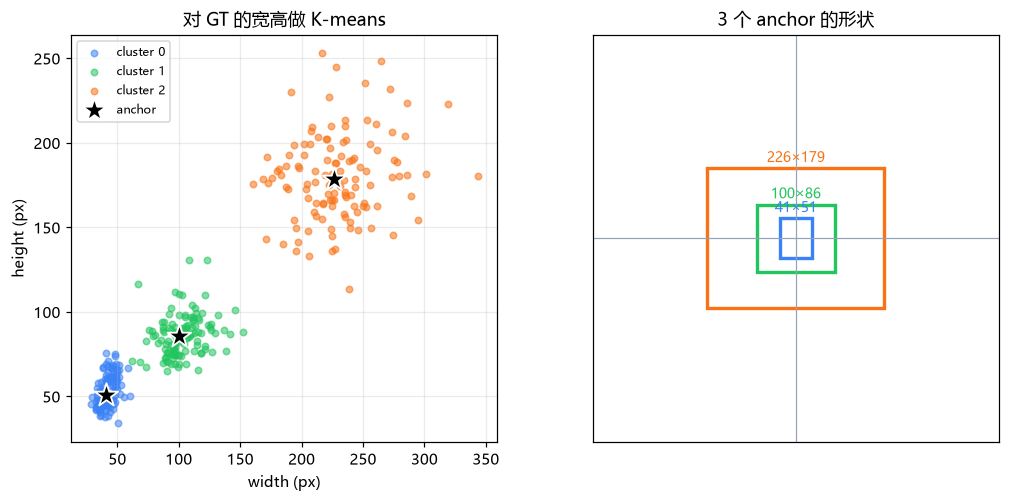

In [15]:
order = np.argsort(anchors[:, 0] * anchors[:, 1])
anchors_sorted = anchors[order]
# 直接按“与哪个 anchor 的 IoU 最大”重新着色，保证颜色和右侧 anchor 一一对应
assign_sorted = iou_wh(wh, anchors_sorted).argmax(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ax = axes[0]
palette = ["#3b82f6", "#22c55e", "#f97316"]
for c in range(3):
    m = assign_sorted == c
    ax.scatter(wh[m, 0], wh[m, 1], s=18, alpha=0.55, color=palette[c],
               label=f"cluster {c}")
ax.scatter(anchors_sorted[:, 0], anchors_sorted[:, 1], marker="*", s=260,
           color="black", edgecolor="white", linewidth=1.2, label="anchor", zorder=5)
ax.set_xlabel("width (px)")
ax.set_ylabel("height (px)")
ax.set_title("对 GT 的宽高做 K-means")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

ax = axes[1]
ax.set_xlim(-260, 260)
ax.set_ylim(260, -260)
ax.set_aspect("equal")
ax.axhline(0, color="#94a3b8", lw=0.8)
ax.axvline(0, color="#94a3b8", lw=0.8)
for c, (w, h) in enumerate(anchors_sorted):
    ax.add_patch(patches.Rectangle((-w / 2, -h / 2), w, h, fill=False,
                                   edgecolor=palette[c], lw=2.2))
    ax.text(0, -h / 2 - 8, f"{w:.0f}×{h:.0f}", ha="center", fontsize=9, color=palette[c])
ax.set_title("3 个 anchor 的形状")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

### 6.1 Anchor-based 与 Anchor-free

| | Anchor-based（YOLOv2–v5） | Anchor-free（YOLOv8 / v10 / v11） |
|---|---|---|
| 每个位置预测 | 相对多个 anchor 的偏移 + objectness | 到框四条边的距离 + 类别分数 |
| 正样本分配 | 与 anchor 的 IoU 最大 / 超过阈值 | 动态分配（如 Task-Aligned Assigner） |
| 超参数 | anchor 尺寸、长宽比、匹配阈值 | 少很多 |
| 典型输出 | `[B, A*(5+C), H, W]` | `[B, 4+C, H, W]` |

YOLOv8 的检测头在每个位置输出 4 个距离（左、上、右、下）和 `C` 个类别分数。它没有 objectness，也不需要预设 anchor。分类和框回归用两个解耦的分支分别预测。

> **不要死记“YOLO = 7×7 网格 + 2 个框”**。那是 YOLOv1。现代 YOLO 仍然是“密集预测 + 单阶段”，但网格、anchor、损失和标签分配都变了。第 03 本会拆开 YOLOv8 的输出。

## 7. 一页总结

| 概念 | 一句话 | 在 YOLO 里的位置 |
|---|---|---|
| `xyxy` / `cxcywh` | 同一个框的不同坐标写法 | 标签解析、画图、NMS |
| IoU | 交并比，衡量两个框重合程度 | 匹配 GT、NMS、mAP |
| NMS | 按分数保留局部最大，压掉重复框 | 后处理 |
| Precision / Recall | 误报少 / 漏报少 | 评价 |
| AP / mAP | PR 曲线面积 / 各类平均 | 评价与选模型 |
| 网格 + 置信度 | 每个格子预测中心落在其中的物体 | YOLOv1 的核心 |
| Anchor | 预置参考框，网络回归偏移 | YOLOv2–v5 |
| Anchor-free | 直接预测到四条边的距离 | YOLOv8+ |

### 自测题

1. 一个框 `xyxy = (40, 60, 140, 160)`，它的 `cxcywh` 是多少？归一化到 `640×480` 后是多少？
2. 两个框的 IoU 是 0.6。NMS 阈值设为 0.5 时，分数低的那个会被保留吗？
3. 为什么 NMS 通常要按类别分别做？
4. `mAP50` 和 `mAP50-95` 的区别是什么？
5. YOLOv1 的 `7×7×30` 里，`30` 是怎么来的？
6. Anchor-based 和 Anchor-free 最本质的区别是什么？

> 下一本：`02_yolov1_from_scratch.ipynb`，我们会用 PyTorch 把这套东西真正实现出来，并在合成数据上训练一个能检测红/绿/蓝三种图形的迷你 YOLO。